# 03-加载T800机器人


## 1. 本课目标：银色机器人第一次亮相

本篇对应《具身智能机器人实战》第 03 节，原课件标题为 **《加载 T800》**，副标题是“银色机器人第一次亮相”，配套视频名为《03_加载T800机器人》。

上一节用方块下落验证了 MuJoCo 的基本物理过程，本节开始接触 T800 模型：认识机器人结构描述，找到模型来源，并读取模型的基本统计参数。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/03_加载 T800.pptx` 全部 5 页，其中第 5 页为品牌结束页，正文依据第 1～4 页整理，图注保留原课件页码。

课件展示了官方仓库和参数含义，没有给出加载脚本或具体模型文件路径。本篇进一步核对该仓库中的 T800 资源，将文件路径、运行示例和参数解释中的必要修正标为“工程补充”。未转录视频，也未读取网盘中的 `code.zip`。


## 2. 机器人模型中的 Link、Joint 与 Motor

课件先区分机器人外观和机器人结构。外观网格、材质和贴图决定模型看起来是什么样子，结构描述则让仿真引擎知道身体如何连接、怎样运动以及如何接受驱动。

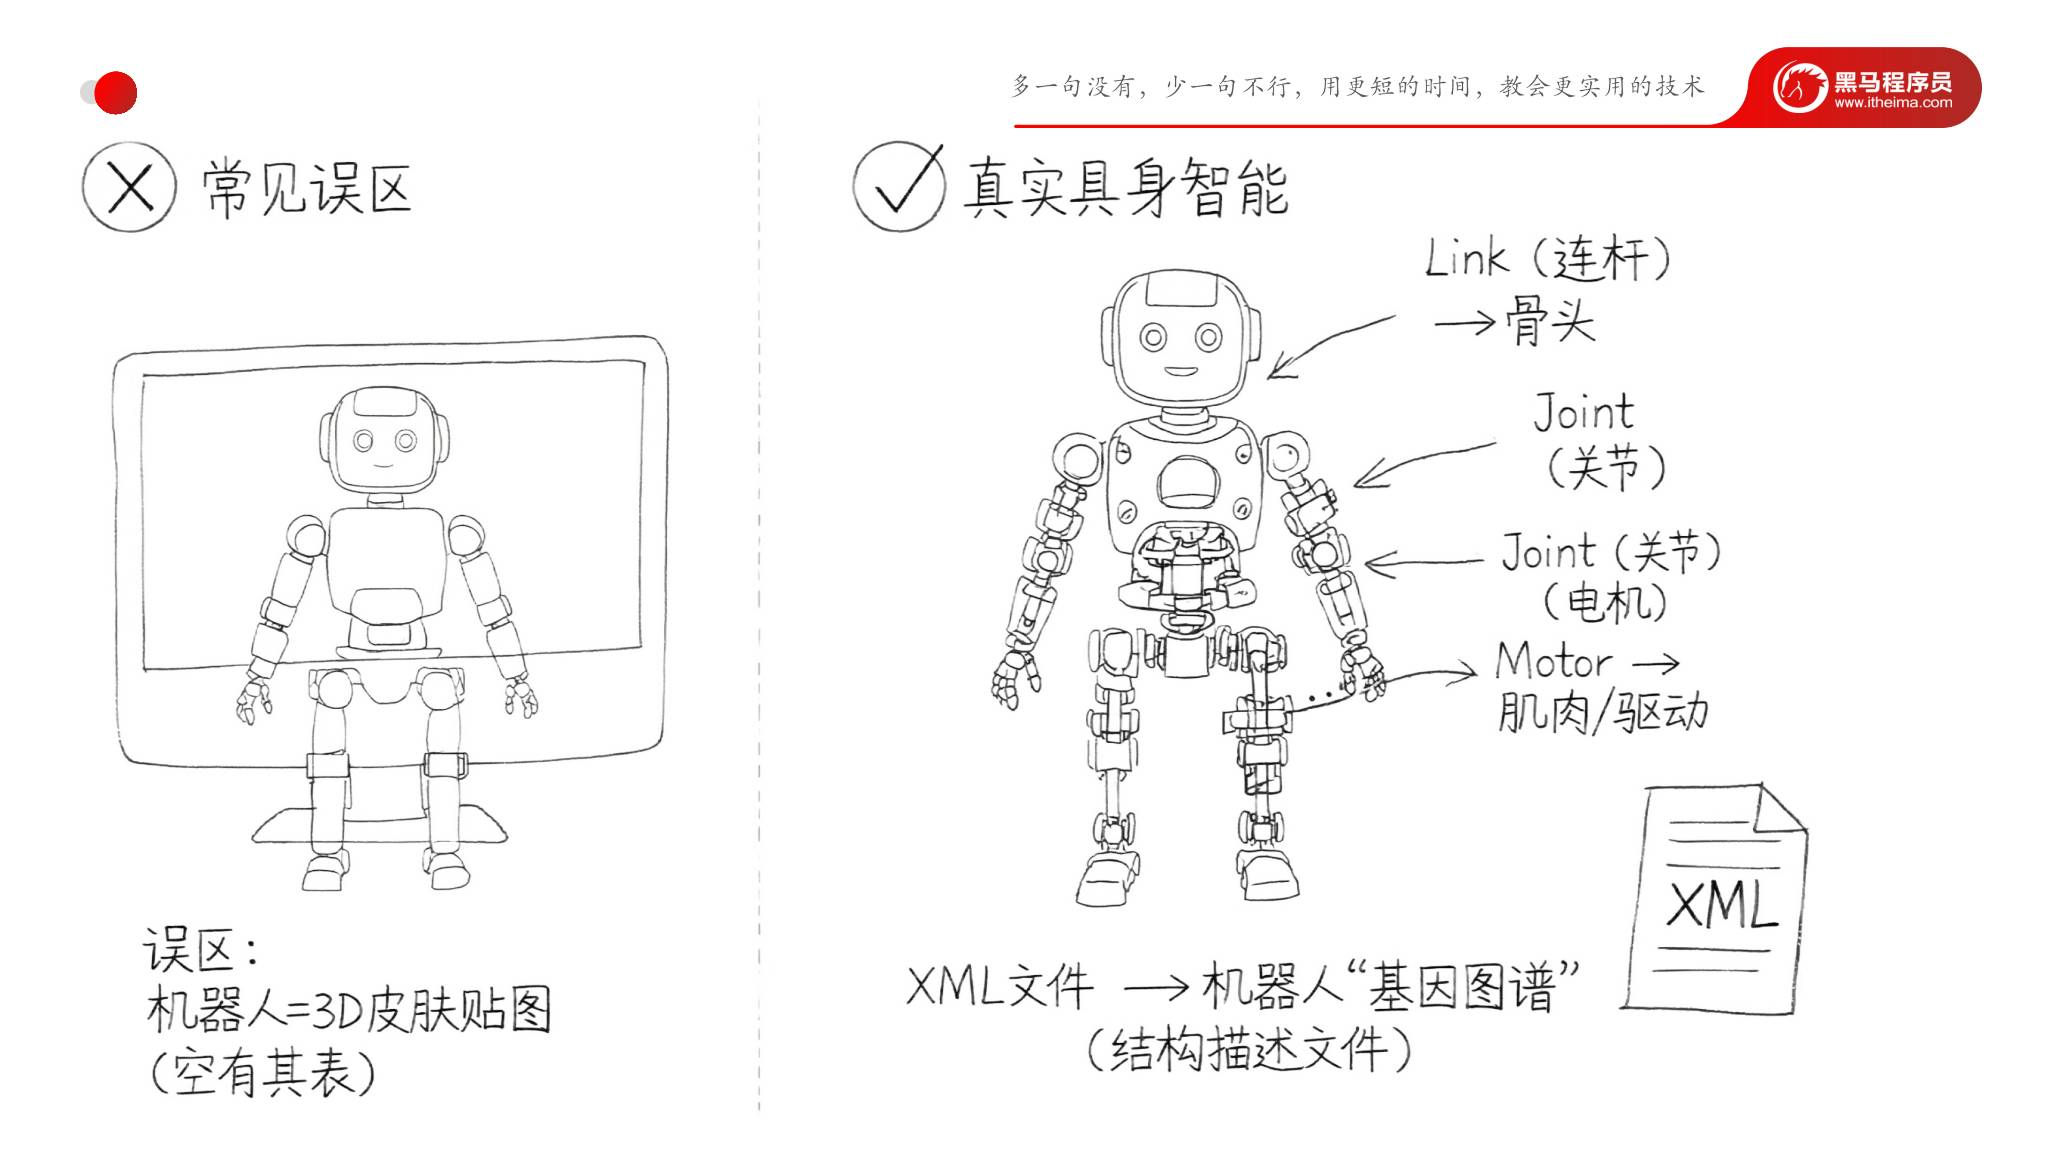

*原课件第 2 页：用骨头、关节和肌肉类比 Link、Joint 与 Motor，并把 XML 称为机器人“基因图谱”。*

| 名称 | 课件中的类比 | 学习时先理解的作用 |
|---|---|---|
| Link，连杆 | 骨头 | 构成机器人的身体部件 |
| Joint，关节 | 骨头之间的连接 | 描述部件之间允许发生的相对运动 |
| Motor，电机 | 肌肉、驱动 | 为运动提供驱动力 |
| XML 结构描述文件 | 机器人“基因图谱” | 组织身体结构、关节与相关物理信息 |

这说明加载机器人需要完整的模型描述。单独拿到一个外观文件，还不足以确定它的关节连接、质量和驱动方式。

**工程补充：**在 MuJoCo 的 MJCF XML 中，刚体部件通常由 `<body>` 描述，外观和碰撞形状由 `<geom>` 等元素描述，运动连接由 `<joint>` 描述，电机驱动可用 `<actuator>` 下的 `<motor>` 描述。关节与电机是不同的模型对象，课件在关节旁标出的“电机”应结合这一点理解。

本节先认识这些名称，下一节再详细学习 T800 的 joint 和 link。


## 3. 模型来源：课件中的官方仓库

第 3 页展示的仓库是：

[engineai-robotics / engineai_robotics_native_sdk](https://github.com/engineai-robotics/engineai_robotics_native_sdk)

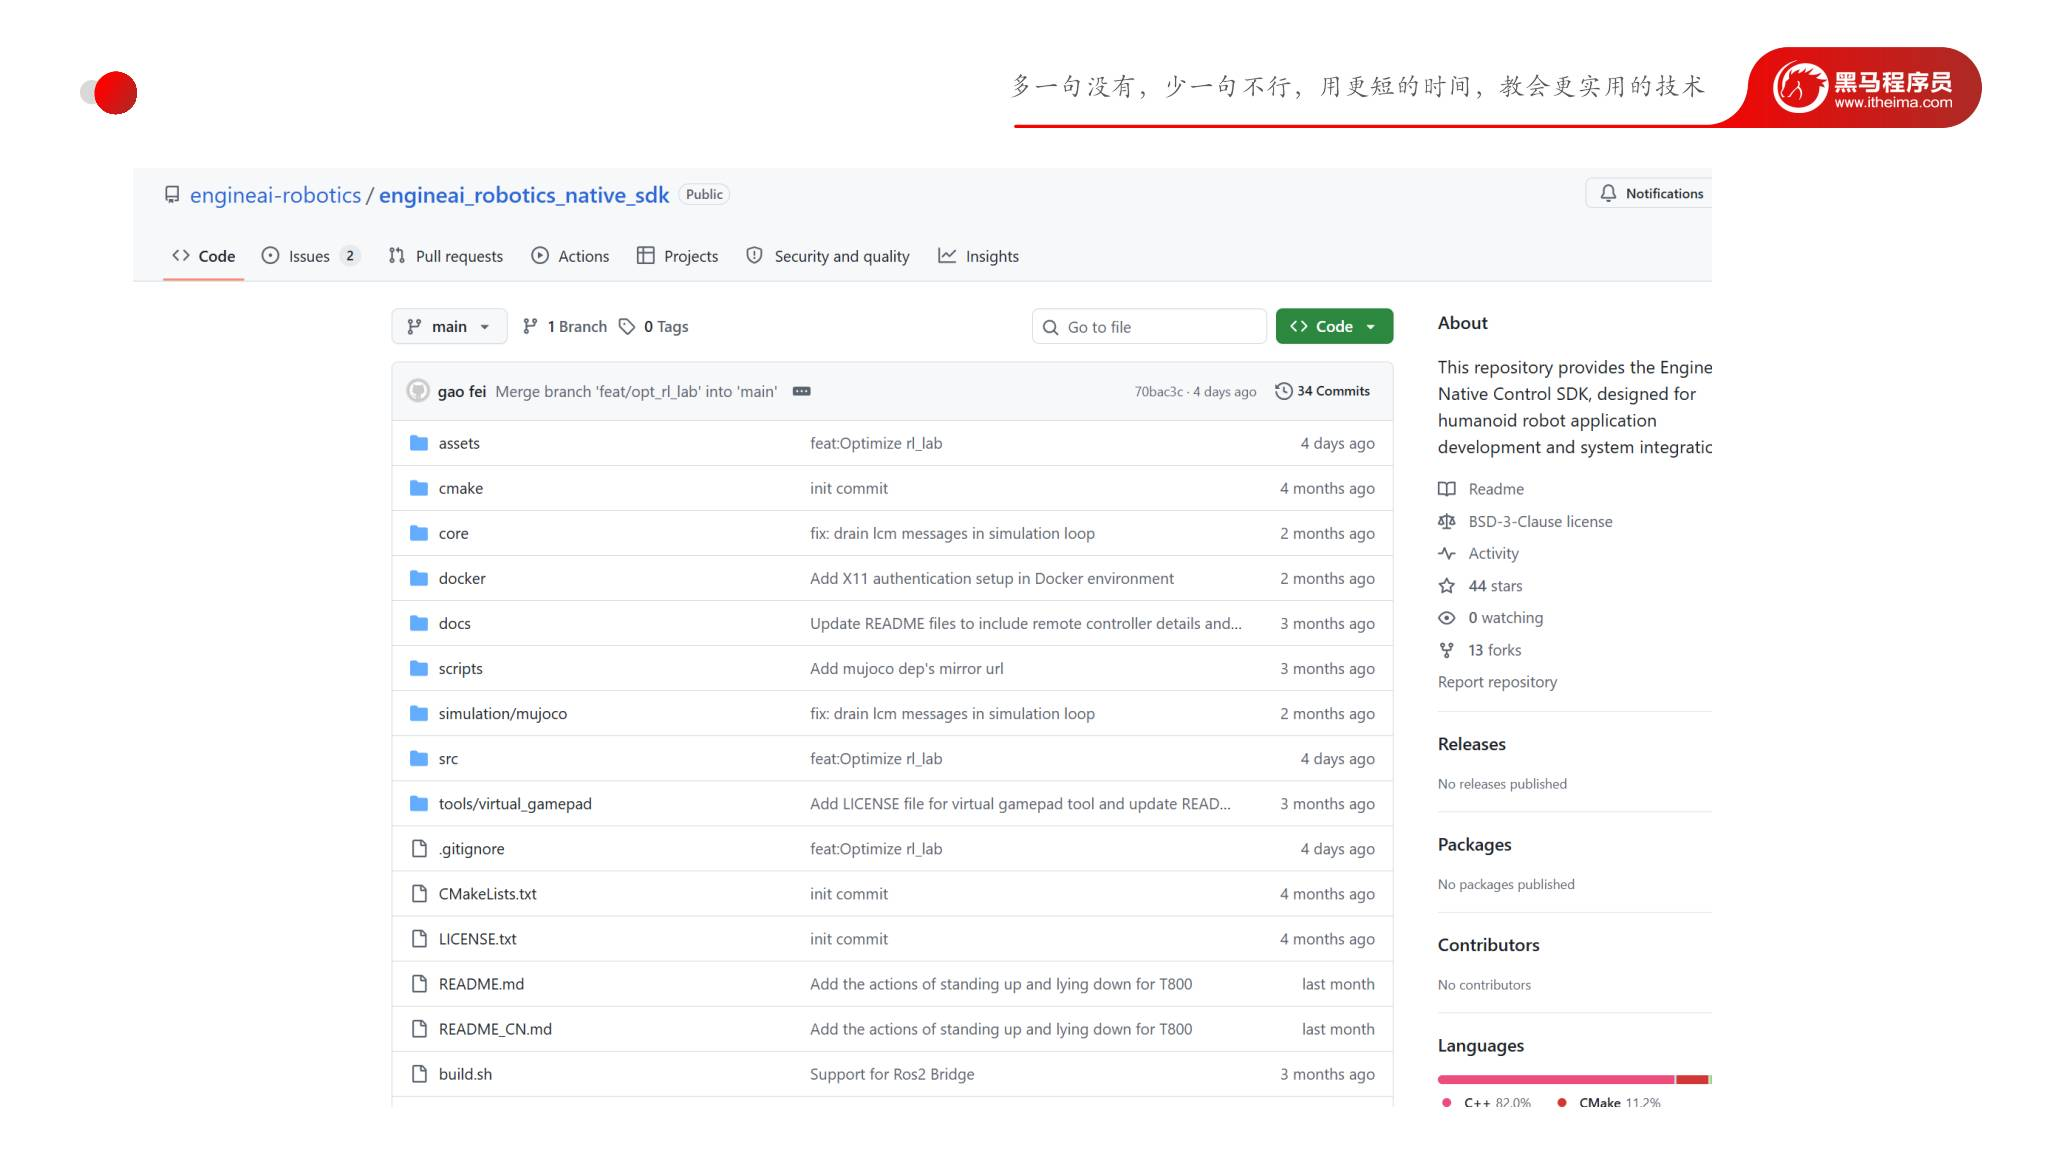

*原课件第 3 页：官方 SDK 仓库首页，包含 assets、simulation/mujoco 等目录。*

仓库提供机器人模型资源和控制开发框架。当前这一步关注能被 MuJoCo 加载的模型资源，先确认机器人可以完整进入场景。

### 工程补充：核对到的 T800 文件

本篇检查的仓库提交为 `335c60e88772c26c7852d0abd6b3c7439037dd8f`。在这个版本中，场景入口与资源分工如下，路径均相对于仓库根目录：

| 路径 | 作用 |
|---|---|
| `assets/resource/t800.xml` | T800 与地面组合后的场景入口 |
| `assets/resource/environment/ground.xml` | 地面、灯光和相关显示设置 |
| `assets/resource/robot/t800/xml/serial_t800.xml` | 机器人模型入口、默认设置和浮动基座 |
| `assets/resource/robot/t800/xml/serial_links.xml` | 身体部件、关节和惯性等描述 |
| `assets/resource/robot/t800/xml/serial_actuators.xml` | 执行器配置 |
| `assets/resource/robot/t800/xml/serial_sensors.xml` | 传感器配置 |
| `assets/resource/robot/t800/xml/assets.xml` | 网格、贴图和材质引用 |
| `assets/resource/robot/t800/meshes/`、`texture/` | 模型加载时引用的外观资源 |

官方 `assets/resource/t800.xml` 的有效内容如下，省略其中未启用的注释示例：

```xml
<mujoco model="global_model">
    <include file="robot/t800/xml/serial_t800.xml"/>
    <include file="environment/ground.xml"/>
</mujoco>
```

入口文件通过 `include` 引用机器人和地面，机器人文件又会引用关节、执行器及资源文件。因此应保留相关目录结构，避免只复制一个 XML 后出现依赖文件缺失。


## 4. 加载后先认识五个模型参数

第 4 页用人体结构类比五个参数，帮助建立模型规模的直觉：

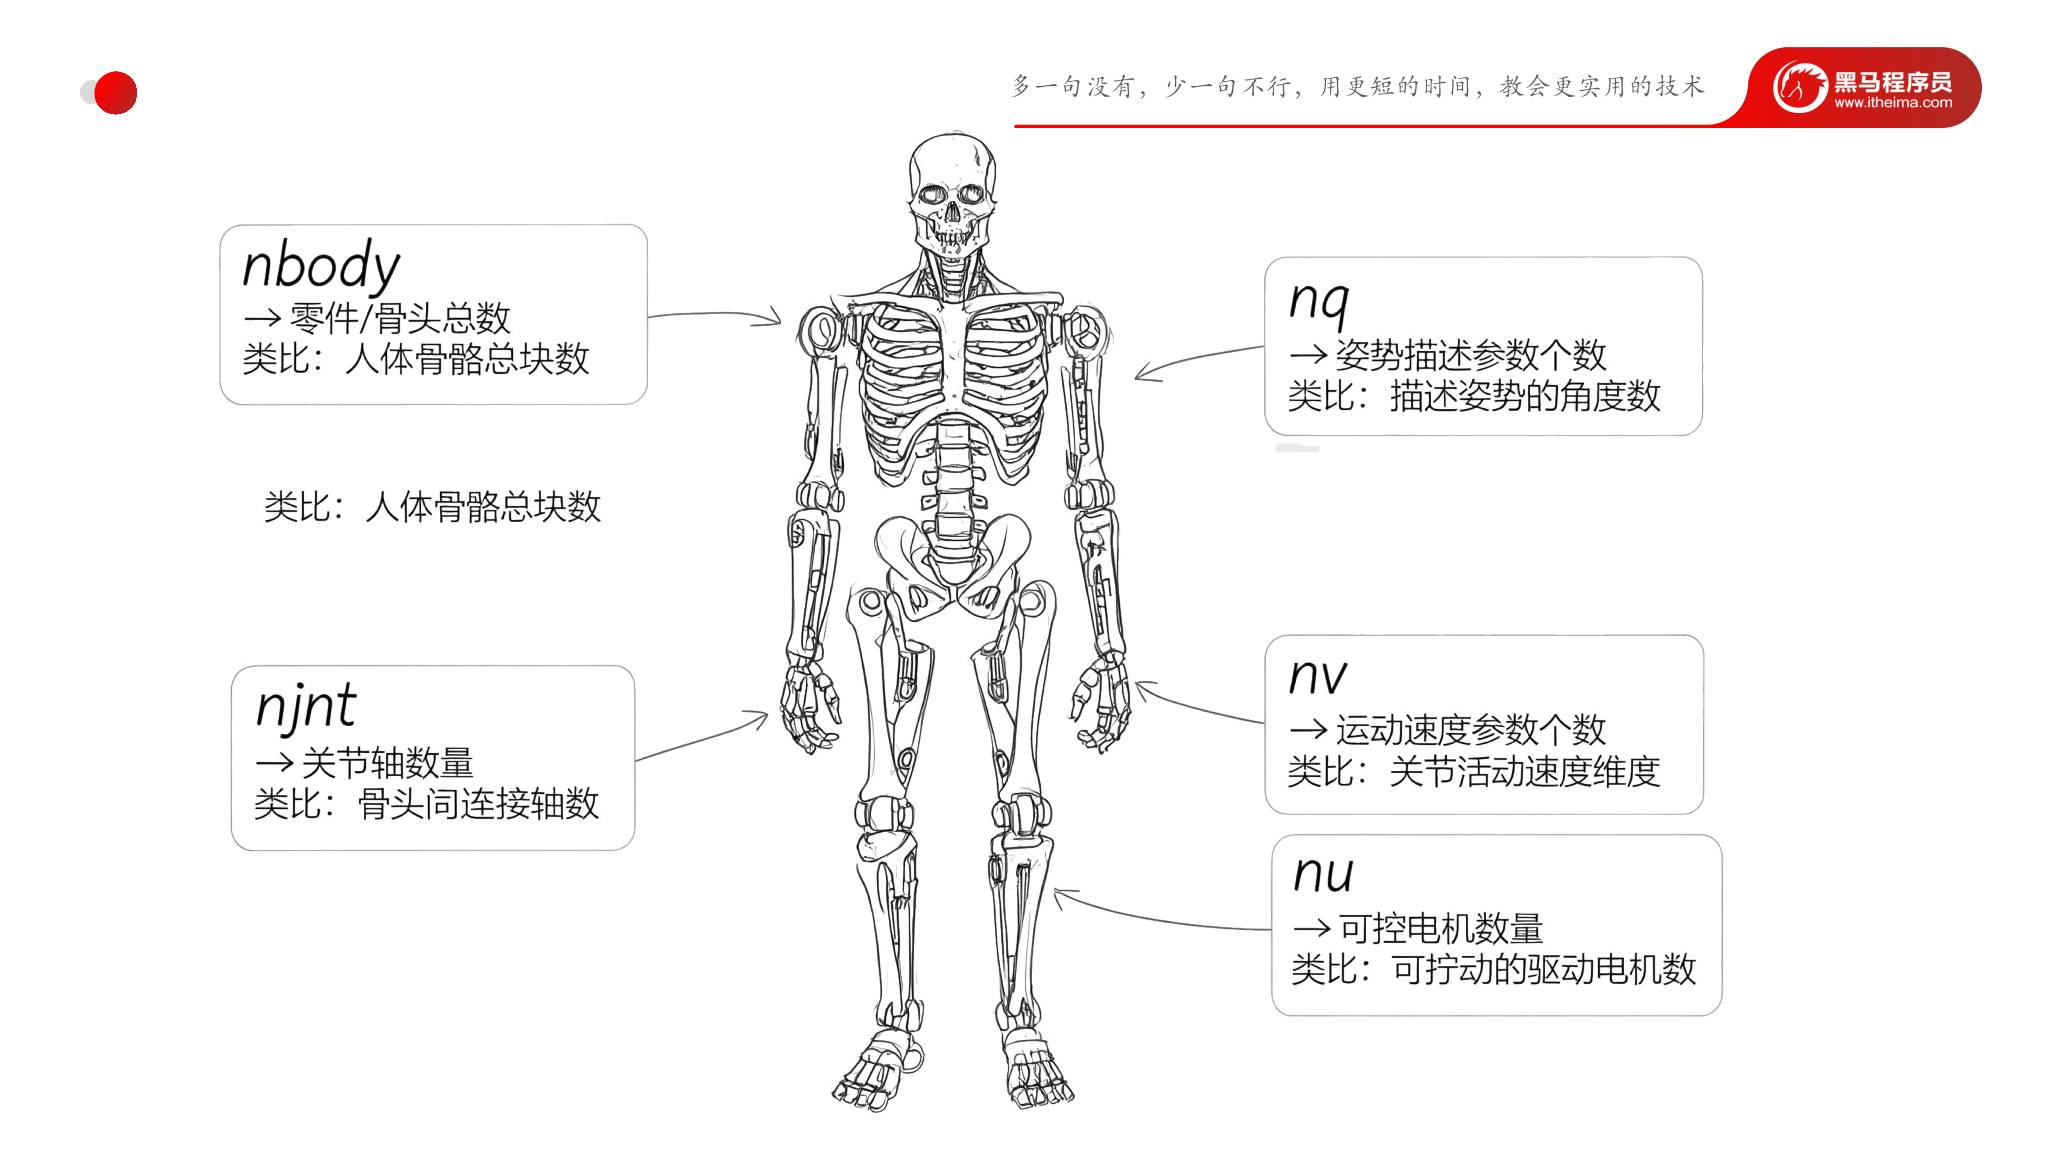

*原课件第 4 页：以骨骼总数、连接、姿态、速度和驱动来解释模型统计参数。图中的“轴数”“角度数”“电机数量”为入门类比，准确含义见下表。*

| 参数 | 课件中的类比 | 工程补充：MuJoCo 中的准确含义 |
|---|---|---|
| `nbody` | 零件、骨头总数 | 模型中的 body 数量，包含 world body（世界体） |
| `njnt` | 关节轴数量 | 关节对象的数量；不同类型关节具有不同自由度 |
| `nq` | 姿势描述参数个数、角度数 | 广义位置坐标数量，等于 `data.qpos` 的长度，可能包含平移和四元数 |
| `nv` | 运动速度参数个数 | 速度自由度数量，等于 `data.qvel` 的长度 |
| `nu` | 可控电机数量 | 执行器及控制输入数量，等于 `data.ctrl` 的长度 |

这些参数描述的是不同对象，通常不能互相替代。尤其不能把 `njnt` 直接当成全部运动自由度，也不能假设 `nq` 中每一个值都是关节角。

### 工程补充：这个 T800 版本为什么有不同的数值

本篇实际加载上述提交中的 `assets/resource/t800.xml`，得到：

| 参数 | 本次读取值 | 对应解释 |
|---|---:|---|
| `nbody` | 31 | 包含世界体的 body 总数 |
| `njnt` | 26 | 25 个单轴转动关节，加 1 个自由关节 |
| `nq` | 32 | 25 个关节角，加基座的 3 个位置坐标和 4 个姿态四元数分量 |
| `nv` | 31 | 25 个关节速度，加基座的 3 个平移速度和 3 个转动速度 |
| `nu` | 25 | 此版本定义的 25 个 motor 执行器 |

自由关节用于描述机器人基座相对于世界的运动，它占用 7 个位置坐标和 6 个速度坐标，所以这里 `nq` 比 `nv` 多 1。四元数用 4 个分量表示三维旋转，并不因此增加一个独立的旋转自由度。

这组值是本篇核对版本的读取结果，**不是课件提供的固定数值，也不代表所有 T800 模型版本**。如果更换模型或修改结构，应重新读取。


## 5. 工程补充：加载并检查官方 T800 场景

课件没有展示代码，下面提供一个与本节目标对应的检查步骤。沿用第 02 篇的 Python 3.11、MuJoCo 3.4.0 环境约定，先完成加载与初始姿态查看。

### 5.1 准备模型与环境

以下为 Windows PowerShell 操作。先在自行选择的练习父目录打开终端，确保可以运行 Git 和 uv，再执行：

```powershell
mkdir t800-load
Set-Location t800-load
uv venv --python 3.11 .venv
uv pip install --python .\.venv\Scripts\python.exe "mujoco==3.4.0" "numpy==2.3.5"
git clone --depth 1 --filter=blob:none --sparse https://github.com/engineai-robotics/engineai_robotics_native_sdk.git engineai_robotics_native_sdk
git -C engineai_robotics_native_sdk sparse-checkout set assets/resource/robot/t800 assets/resource/environment
```

这里使用 Git 的稀疏检出，只取 T800 及地面相关目录，所需父目录中的场景入口也会保留。它是为本节补充的资源获取方式。已有完整官方仓库时可以直接使用其中的资源。

仓库会更新，以上命令取得当前主分支。可以记录本地版本，便于解释参数差异：

```powershell
git -C engineai_robotics_native_sdk rev-parse HEAD
```

准备完成后，应能找到 `engineai_robotics_native_sdk/assets/resource/t800.xml`，以及它所引用的机器人、地面、网格和贴图文件。此处无需编译完整 SDK。

### 5.2 创建 load_t800.py

在 `t800-load` 目录中新建 `load_t800.py`。它默认查找同目录下的官方仓库，也允许通过 `--model` 指定已有的场景入口。

```python
import argparse
import time
from pathlib import Path

import mujoco
import mujoco.viewer


def main():
    default_model = (
        Path(__file__).resolve().parent
        / "engineai_robotics_native_sdk"
        / "assets"
        / "resource"
        / "t800.xml"
    )
    parser = argparse.ArgumentParser(description="加载并检查 T800 模型")
    parser.add_argument("--model", type=Path, default=default_model)
    parser.add_argument("--view", action="store_true", help="查看初始姿态")
    args = parser.parse_args()

    model_path = args.model.expanduser().resolve()
    if not model_path.is_file():
        raise FileNotFoundError(f"场景入口不存在：{model_path}")

    model = mujoco.MjModel.from_xml_path(str(model_path))
    data = mujoco.MjData(model)
    mujoco.mj_forward(model, data)

    for name in ("nbody", "njnt", "nq", "nv", "nu"):
        print(f"{name} = {getattr(model, name)}")
    print(f"qpos.shape = {data.qpos.shape}")
    print(f"qvel.shape = {data.qvel.shape}")
    print(f"ctrl.shape = {data.ctrl.shape}")

    if args.view:
        with mujoco.viewer.launch_passive(model, data) as viewer:
            while viewer.is_running():
                viewer.sync()
                time.sleep(0.02)


if __name__ == "__main__":
    main()
```

`resolve()` 将场景路径转换为绝对路径，入口 XML 内的引用继续由 MuJoCo 按模型文件位置处理。`MjModel.from_xml_path()` 编译模型，`MjData(model)` 创建数据，`mj_forward()` 计算当前姿态下的派生信息。

这里没有调用 `mj_step()`，因此不会推进仿真时间。查看器保持初始姿态，便于核对外观和资源加载情况，当前步骤还没有加入站立或行走控制。

### 5.3 运行并核对参数

在 `t800-load` 目录执行：

```powershell
.\.venv\Scripts\python.exe load_t800.py
```

本篇在已注明的官方模型提交上实际读取到以下输出：

```text
nbody = 31
njnt = 26
nq = 32
nv = 31
nu = 25
qpos.shape = (32,)
qvel.shape = (31,)
ctrl.shape = (25,)
```

这说明模型已成功编译，状态数组的长度与相应参数一致。继续查看初始姿态：

```powershell
.\.venv\Scripts\python.exe load_t800.py --view
```

预期打开场景窗口，看到完整的 T800 和地面；关闭窗口后退出。若模型外观不完整或加载失败，先查看报错指向的资源文件。

### 5.4 常见检查位置

| 现象 | 检查内容 |
|---|---|
| 场景入口不存在 | 仓库是否放在脚本旁边，入口是否为 `assets/resource/t800.xml` |
| 无法打开 include、网格或贴图文件 | 是否只复制了一个 XML，是否保留原来的相对目录结构 |
| 参数与本篇不同 | `rev-parse HEAD`、实际加载路径与模型版本是否相同 |
| 终端能打印参数，图形窗口打不开 | 查看器报错以及本机 OpenGL、显示环境 |
| 机器人保持不动 | 本示例只查看初始姿态；运动控制在后续课程中展开 |


## 6. 本课完成标准与补充参考

完成本节，应能说明机器人结构描述与外观资源的关系，找到官方模型入口，成功加载场景，并区分 `nbody、njnt、nq、nv、nu` 的含义。

本篇补充脚本已在 MuJoCo 3.4.0 中实际加载官方 T800 模型，核对了五个统计参数及 `qpos、qvel、ctrl` 的维数。此次没有打开图形窗口，也未验证站立、行走或真实硬件。

用于核对路径和参数的参考：

- [本篇核对版本的 T800 场景入口](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/t800.xml)。
- [同版本的机器人 XML 目录](https://github.com/engineai-robotics/engineai_robotics_native_sdk/tree/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml)。
- [MuJoCo 3.4.0：mjModel 字段定义](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APItypes.html#mjmodel)。
- [MuJoCo 3.4.0：关节与广义坐标](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#body-joint)。
- [MuJoCo 3.4.0：Python 模型加载与查看器](https://mujoco.readthedocs.io/en/3.4.0/python.html)。

下一节继续认识 T800 的 joint 和 link，把本节的整体模型对应到具体部件。
